# Propensity Scores, IPW, and Doubly Robust Estimation

**What you'll learn**

- How badly a naive treated-vs-untreated comparison fails on confounded observational data — quantified against a simulated ground truth.
- How to fit a propensity score, diagnose overlap/common support, trim, and verify the *balancing-score* property directly.
- Four workhorse estimators — PS stratification, nearest-neighbor matching, IPW (Horvitz–Thompson vs stabilized/Hajek), and outcome regression — implemented from scratch and scored against the known ATE/ATT.
- Doubly robust AIPW: why it survives misspecification of *either* the propensity model *or* the outcome model (but not both), demonstrated in a Monte Carlo "money experiment".
- The diagnostics that actually matter: standardized mean differences and love plots, effective sample size, weight distributions — and why propensity-model AUC is the *wrong* success criterion.
- Pitfalls that kill real analyses: conditioning on post-treatment variables, unobserved confounding (with a sensitivity curve), extreme weights.

**Why it matters in interviews**

- "We launched the promo/feature to everyone (or targeting chose who got it) — no experiment possible. Estimate the effect" is a staple senior-DS case question; this notebook is the standard playbook.
- "What does doubly robust mean / buy you?" and "how do you validate a propensity model?" are classic depth probes that separate people who have *used* these methods from people who have read about them.
- Weighting pathologies (extreme weights, positivity violations) are where interviewers check whether you understand the *assumptions*, not just the formulas.

Identification concepts (potential outcomes, DAGs, which covariates belong in the adjustment set)
are covered in [01_potential_outcomes_dags.ipynb](01_potential_outcomes_dags.ipynb) — here we take
a valid adjustment set as given and focus on **estimation**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import cross_val_predict, KFold

rng = np.random.default_rng(42)  # master seed for the main sample
# Monte Carlo experiments below use their own explicitly-seeded generators so each
# experiment is reproducible in isolation. Everything is deterministic end to end.

plt.rcParams.update({
    "figure.figsize": (9.0, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. The setting: a promo campaign with no holdout

Marketing sent a spend-boosting promo to a **targeted** subset of users — no randomized
holdout. We want the causal effect of the promo on next-month spend.

The simulation bakes in exactly the confounding structure that makes this hard:
**engaged users are more likely to receive the promo AND would have spent more anyway.**

- Covariates: `sessions_wk` (weekly sessions), `tenure_m` (months on platform), `past_spend`
  ($/month, log-normal — a long right tail, like every real spend variable).
- Treatment (`promo`): logistic in sessions, log past spend, a "power user" jump at
  5 sessions/week, and tenure. Targeting is *stochastic* — crucial for overlap.
- Outcome (`spend_next`): baseline spend driven by the same variables (log spend enters
  linearly, i.e. raw spend enters *nonlinearly*), plus a heterogeneous treatment effect
  $\tau(x) = 12 + 1.5\,(\text{sessions} - 3.2)$: the promo works better on engaged users.

Because we simulate, every user carries oracle columns (`e_true`, `tau`, `y0`) that a real
analyst never sees. They give us the **true ATE** ($E[\tau(X)]$) and **true ATT**
($E[\tau(X) \mid T{=}1]$) to score every estimator against. Note ATT > ATE by construction:
targeting selects engaged users, and the effect is larger for them.

In [2]:
def make_campaign(n, rng, strength=1.0, intercept=-2.9, gamma_u=0.0):
    """Simulate the observational promo campaign.

    strength scales how aggressively targeting depends on covariates (overlap knob);
    gamma_u adds an *unobserved* confounder u (used in the sensitivity section).
    """
    s = rng.gamma(2.0, 1.6, n)                                   # sessions per week
    tenure = rng.uniform(1, 36, n)                               # months on platform
    spend = np.exp(2.4 + 0.30 * s + rng.normal(0, 0.6, n))       # past monthly spend ($)
    ls = np.log1p(spend)
    power = (s > 5).astype(float)                                # "power user" flag
    u = rng.normal(0, 1, n)                                      # unobserved trait (off by default)

    logit = intercept + strength * (0.36 * s + 0.72 * (ls - 3.4)
                                    + 0.5 * power + 0.012 * tenure) + gamma_u * u
    e_true = 1.0 / (1.0 + np.exp(-logit))                        # true propensity score
    T = rng.binomial(1, e_true)

    tau = 12.0 + 1.5 * (s - 3.2)                                 # heterogeneous true effect
    y0 = (40 + 16 * (ls - 3.4) + 3.0 * s + 5 * power + 0.08 * tenure
          + 4.0 * gamma_u * u + rng.normal(0, 20, n))            # untreated potential outcome
    Y = np.where(T == 1, y0 + tau, y0)

    return pd.DataFrame({
        "sessions_wk": s, "tenure_m": tenure, "past_spend": spend,
        "log_spend": ls, "power_user": power,
        "promo": T, "spend_next": Y,
        # oracle columns (only exist because we simulated):
        "e_true": e_true, "tau": tau, "y0": y0,
    })


df = make_campaign(20_000, rng)
OBSERVED = ["sessions_wk", "tenure_m", "past_spend", "log_spend", "power_user"]
CONFOUNDERS = ["sessions_wk", "power_user", "log_spend", "tenure_m"]  # correct adjustment set

true_ate = df["tau"].mean()
true_att = df.loc[df["promo"] == 1, "tau"].mean()
print(f"n = {len(df):,}, treated share = {df['promo'].mean():.1%}")
print(f"true ATE = {true_ate:.2f} $/user   true ATT = {true_att:.2f} $/user")
q = df["e_true"].quantile([0.01, 0.50, 0.99])
print(f"true propensity quantiles (1% / 50% / 99%): {q.iloc[0]:.3f} / {q.iloc[1]:.3f} / {q.iloc[2]:.3f}")
df[OBSERVED[:3] + ["promo", "spend_next"]].head()

n = 20,000, treated share = 25.0%
true ATE = 12.03 $/user   true ATT = 15.22 $/user
true propensity quantiles (1% / 50% / 99%): 0.026 / 0.145 / 0.968


,sessions_wk,tenure_m,past_spend,promo,spend_next
0,3.347,2.856,43.143,1,74.539
1,4.537,16.050,53.747,1,94.490
2,2.940,7.744,124.043,0,31.225
3,2.632,5.424,27.704,0,66.678
4,4.927,29.124,32.429,0,51.546


### How badly does the naive comparison fail?

In [3]:
naive = df.loc[df["promo"] == 1, "spend_next"].mean() - df.loc[df["promo"] == 0, "spend_next"].mean()
print(f"naive difference in means : {naive:+.2f} $/user")
print(f"true ATE                  : {true_ate:+.2f} $/user")
print(f"selection bias            : {naive - true_ate:+.2f} $/user "
      f"-> naive overstates the effect ~{naive / true_ate:.1f}x")

balance_raw = df.groupby("promo")[OBSERVED + ["spend_next"]].mean().T
balance_raw.columns = ["control", "treated"]
print("\nGroup means (why the naive comparison lies):")
print(balance_raw.round(2).to_string())

naive difference in means : +42.06 $/user
true ATE                  : +12.03 $/user
selection bias            : +30.03 $/user -> naive overstates the effect ~3.5x

Group means (why the naive comparison lies):
             control  treated
sessions_wk    2.510    5.340
tenure_m      18.290   19.150
past_spend    29.610  108.380
log_spend      3.160    4.160
power_user     0.070    0.530
spend_next    45.600   87.650


The promo group spends far more — but they were *selected* for being high-engagement,
high-spend users. Roughly three quarters of the naive "effect" is selection bias.
Presenting the naive delta as campaign ROI is the single most common (and most expensive)
observational-analysis error in industry.

## 2. Propensity scores

The propensity score is $e(x) = P(T{=}1 \mid X{=}x)$. Two facts make it useful
(Rosenbaum & Rubin, 1983):

1. **Balancing score**: $T \perp X \mid e(X)$. Among users with the same propensity,
   treatment is as-if random with respect to $X$ — a 1-dimensional summary is enough to
   balance an arbitrary-dimensional covariate vector.
2. **Identification**: if unconfoundedness holds given $X$
   ($(Y_1, Y_0) \perp T \mid X$) and positivity holds ($0 < e(x) < 1$), then adjusting
   for the scalar $e(X)$ identifies causal effects.

The PS does **not** fix unobserved confounding — it only compresses the *observed*
adjustment set. We fit a logistic regression on the correct adjustment set
(sessions, power-user flag, **log** spend, tenure — matching the true functional form,
a luxury we get to relax later).

PS model AUC (descriptive only!)      : 0.833
AUC of the TRUE propensity score      : 0.833
corr(estimated PS, true PS)           : 1.000


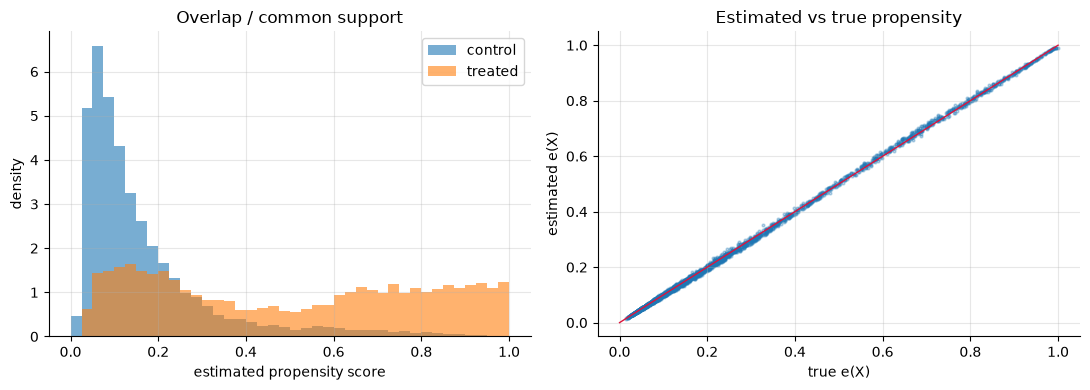

In [4]:
def fit_ps(data, cols, clip=0.01):
    """Logistic-regression propensity scores, clipped away from 0/1."""
    model = LogisticRegression(C=1e6, solver="newton-cholesky", max_iter=500)
    model.fit(data[cols], data["promo"])
    return np.clip(model.predict_proba(data[cols])[:, 1], clip, 1 - clip)


df["ps"] = fit_ps(df, CONFOUNDERS)

print(f"PS model AUC (descriptive only!)      : {roc_auc_score(df['promo'], df['ps']):.3f}")
print(f"AUC of the TRUE propensity score      : {roc_auc_score(df['promo'], df['e_true']):.3f}")
print(f"corr(estimated PS, true PS)           : {np.corrcoef(df['ps'], df['e_true'])[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 1, 41)
axes[0].hist(df.loc[df["promo"] == 0, "ps"], bins=bins, alpha=0.6, density=True, label="control")
axes[0].hist(df.loc[df["promo"] == 1, "ps"], bins=bins, alpha=0.6, density=True, label="treated")
axes[0].set(title="Overlap / common support", xlabel="estimated propensity score", ylabel="density")
axes[0].legend()

idx = rng.choice(len(df), 3000, replace=False)
axes[1].scatter(df["e_true"].iloc[idx], df["ps"].iloc[idx], s=4, alpha=0.3)
axes[1].plot([0, 1], [0, 1], color="crimson", lw=1)
axes[1].set(title="Estimated vs true propensity", xlabel="true e(X)", ylabel="estimated e(X)")
plt.tight_layout()
plt.show()

Read the left panel like an interviewer would:

- **Both histograms occupy the same support** — for (almost) every treated user there exist
  comparable controls. That is what makes adjustment possible at all.
- The distributions are *shifted* (treated concentrate at higher PS) — that is just the
  confounding we must correct.
- Danger signs would be: treated mass where control density is ~0 (no counterfactuals) or
  spikes at 0/1 (near-deterministic targeting → positivity failure).

### Trimming to common support

Users with extreme scores contribute counterfactuals that the data cannot support, and
their weights ($1/e$ or $1/(1-e)$) explode. Standard practice: **trim** to
$\hat e \in [0.02, 0.98]$ (thresholds are conventions; Crump et al. 2009 suggest ~0.1
for heavy cases). Be explicit in write-ups: trimming **changes the estimand** to the
population with genuine overlap — usually the honest population to talk about anyway.

In [5]:
keep = df["ps"].between(0.02, 0.98)
dfa = df[keep].reset_index(drop=True).copy()   # analysis sample from here on

true_ate_t = dfa["tau"].mean()
true_att_t = dfa.loc[dfa["promo"] == 1, "tau"].mean()
print(f"trimmed {(~keep).sum()} of {len(df):,} users ({(~keep).mean():.2%}) with PS outside [0.02, 0.98]")
print(f"analysis sample n = {len(dfa):,}, treated = {dfa['promo'].sum():,}")
print(f"true ATE on analysis sample = {true_ate_t:.2f}   true ATT = {true_att_t:.2f}")
print("(these are the truths every estimator below is scored against)")

trimmed 166 of 20,000 users (0.83%) with PS outside [0.02, 0.98]
analysis sample n = 19,834, treated = 4,874
true ATE on analysis sample = 11.95   true ATT = 14.92
(these are the truths every estimator below is scored against)


### Verifying the balancing-score property

The theory says covariates should be balanced *conditional on* $e(X)$. Check it: slice the
sample into propensity deciles and compare covariate means by arm **within** each stratum,
using the standardized mean difference
$\mathrm{SMD} = (\bar x_1 - \bar x_0) / \sqrt{(s_1^2 + s_0^2)/2}$.

In [6]:
def smd(x, t, w=None):
    """(Weighted) standardized mean difference of covariate x between arms t=1 and t=0."""
    if w is None:
        w = np.ones(len(x))
    m1 = np.average(x[t == 1], weights=w[t == 1])
    m0 = np.average(x[t == 0], weights=w[t == 0])
    v1 = np.average((x[t == 1] - m1) ** 2, weights=w[t == 1])
    v0 = np.average((x[t == 0] - m0) ** 2, weights=w[t == 0])
    return (m1 - m0) / np.sqrt((v1 + v0) / 2)


dfa["stratum"] = pd.qcut(dfa["ps"], 10, labels=False)
rows = []
for k, grp in dfa.groupby("stratum"):
    t, s_arr, l_arr = grp["promo"].to_numpy(), grp["sessions_wk"].to_numpy(), grp["log_spend"].to_numpy()
    rows.append({
        "stratum": k, "n": len(grp), "n_treated": int(t.sum()),
        "sess_ctrl": s_arr[t == 0].mean(), "sess_treat": s_arr[t == 1].mean(),
        "SMD_sessions": smd(s_arr, t), "SMD_log_spend": smd(l_arr, t),
    })
strata_tab = pd.DataFrame(rows).set_index("stratum")
print(strata_tab.round(3).to_string())

T_arr = dfa["promo"].to_numpy()
marg_s = smd(dfa["sessions_wk"].to_numpy(), T_arr)
marg_l = smd(dfa["log_spend"].to_numpy(), T_arr)
within_s = strata_tab["SMD_sessions"].abs()
within_l = strata_tab["SMD_log_spend"].abs()
print(f"\nsessions_wk : marginal SMD {marg_s:+.2f}  ->  within-stratum mean |SMD| {within_s.mean():.2f} (max {within_s.max():.2f})")
print(f"log_spend   : marginal SMD {marg_l:+.2f}  ->  within-stratum mean |SMD| {within_l.mean():.2f} (max {within_l.max():.2f})")

            n  n_treated  sess_ctrl  sess_treat  SMD_sessions  SMD_log_spend
stratum                                                                     
0        1984         74      0.887       0.879        -0.016          0.340
1        1983        125      1.270       1.253        -0.029          0.088
2        1983        155      1.645       1.635        -0.014          0.004
3        1984        187      2.008       2.073         0.088         -0.029
4        1983        248      2.404       2.406         0.003          0.013
5        1983        332      2.872       2.890         0.024         -0.020
6        1984        447      3.381       3.382         0.001          0.067
7        1983        596      4.051       4.114         0.087          0.034
8        1983       1068      5.325       5.509         0.236          0.051
9        1984       1642      7.070       7.817         0.532          0.525

sessions_wk : marginal SMD +1.27  ->  within-stratum mean |SMD| 0.10 (max 0

Marginal imbalance above 1 SD collapses by an order of magnitude within strata — the
balancing property at work. It is not perfect: deciles are *coarse* bins of a continuous
score, and the widest bins (the extremes) retain residual within-stratum imbalance. That
residual is exactly why stratification is only approximately unbiased — measured next.

## 3. The estimator zoo, scored against the truth

Four classical estimators, all using the same estimated PS or the same covariates. Keep
the **estimand** straight: stratification/IPW/regression as implemented here target the
**ATE**; matching each treated user to controls targets the **ATT**. In this DGP they
genuinely differ (targeting selects users with larger effects), so each estimator is scored
against *its own* truth.

### 3a. Stratification on the propensity score

Estimate a difference in means within each PS stratum, then average — weighted by stratum
size for the ATE, by treated count for the ATT. Cochran's classic result: ~5 strata remove
roughly 90% of the bias. More strata cut residual bias further but thin out the data.

In [7]:
def stratified_estimate(data, n_strata):
    d = data.assign(stratum=pd.qcut(data["ps"], n_strata, labels=False, duplicates="drop"))
    recs = []
    for _, grp in d.groupby("stratum"):
        n1, n0 = int(grp["promo"].sum()), int((1 - grp["promo"]).sum())
        if n1 == 0 or n0 == 0:            # stratum with one arm only: drop (and say so)
            continue
        diff = (grp.loc[grp["promo"] == 1, "spend_next"].mean()
                - grp.loc[grp["promo"] == 0, "spend_next"].mean())
        recs.append((len(grp), n1, diff))
    r = pd.DataFrame(recs, columns=["n", "n1", "diff"])
    ate = (r["diff"] * r["n"]).sum() / r["n"].sum()
    att = (r["diff"] * r["n1"]).sum() / r["n1"].sum()
    return ate, att


print(f"{'strata':>6} | {'ATE est':>8} (true {true_ate_t:.2f}) | {'ATT est':>8} (true {true_att_t:.2f})")
for K in [5, 10, 20, 50]:
    ate_k, att_k = stratified_estimate(dfa, K)
    print(f"{K:>6} | {ate_k:>8.2f}              | {att_k:>8.2f}")
strat_ate10, strat_att10 = stratified_estimate(dfa, 10)

strata |  ATE est (true 11.95) |  ATT est (true 14.92)
     5 |    14.38              |    20.82
    10 |    12.63              |    17.54
    20 |    12.01              |    16.13
    50 |    11.61              |    14.98


The ATE converges quickly; the ATT needs finer strata because treated users pile up in the
top strata, exactly where the bins are widest and residual confounding is largest. This
coarseness is why modern practice prefers weighting or DR estimators — stratification
survives mostly as a transparent diagnostic.

### 3b. Nearest-neighbor matching (1-NN on the PS, with replacement)

For each treated user, find the control with the closest propensity (matching on the
*logit* of the PS is standard — it stretches the tails where matches are hardest) and
average the pairwise outcome differences. This estimates the **ATT**: we reweight controls
to look like the treated, never the reverse.

In [8]:
lp = np.log(dfa["ps"] / (1 - dfa["ps"])).to_numpy().reshape(-1, 1)
Y_arr = dfa["spend_next"].to_numpy()
is_t = T_arr == 1

nn = NearestNeighbors(n_neighbors=1).fit(lp[~is_t])
dist, idx = nn.kneighbors(lp[is_t])
att_match = (Y_arr[is_t] - Y_arr[~is_t][idx.ravel()]).mean()

print(f"1-NN matching ATT = {att_match:.2f}   (true ATT {true_att_t:.2f})")
print(f"worst match distance (logit scale)   : {dist.max():.3f}  -> a caliper (e.g. 0.2 SD) would prune bad matches")
print(f"distinct controls used               : {len(np.unique(idx)):,} of {int((~is_t).sum()):,} "
      "(with replacement; reuse inflates variance)")

1-NN matching ATT = 14.54   (true ATT 14.92)
worst match distance (logit scale)   : 0.466  -> a caliper (e.g. 0.2 SD) would prune bad matches
distinct controls used               : 2,665 of 14,960 (with replacement; reuse inflates variance)


Solid and interpretable ("each promo user vs their statistical twin"), but note two senior
points: (1) matching with replacement reuses a small subset of controls, so naive SEs are
wrong (Abadie–Imbens corrections or the bootstrap-over-the-whole-procedure are needed);
(2) 1-NN throws away most of the control sample — statistically inefficient relative to
weighting.

### 3c. IPW — and the extreme-weights problem

Weighting each user by the inverse probability of the arm they actually got creates a
pseudo-population in which treatment is independent of $X$:

$$\hat\tau_{HT} = \frac{1}{n}\sum_i \frac{T_i Y_i}{\hat e_i} - \frac{1}{n}\sum_i \frac{(1-T_i) Y_i}{1 - \hat e_i}$$

The raw Horvitz–Thompson form divides by $n$ and is notoriously unstable: weights
$1/\hat e$ blow up for treated users with small $\hat e$, and the weighted sums need not
even average the weights to 1. The **Hajek / self-normalized** version divides by the sum
of weights in each arm (equivalently, uses *stabilized* weights $P(T{=}1)/\hat e$ — same
point estimate after normalization). Same asymptotics, far better finite-sample behavior.

In [9]:
def ipw_ht(y, t, e):
    return (t * y / e).mean() - ((1 - t) * y / (1 - e)).mean()


def ipw_hajek(y, t, e):
    w1, w0 = t / e, (1 - t) / (1 - e)
    return (w1 * y).sum() / w1.sum() - (w0 * y).sum() / w0.sum()


def ess(w):
    """Kish effective sample size of a weighted sample."""
    return w.sum() ** 2 / (w ** 2).sum()


e_hat = dfa["ps"].to_numpy()
w_treated = 1 / e_hat[is_t]
w_control = 1 / (1 - e_hat[~is_t])

print(f"IPW Horvitz-Thompson ATE = {ipw_ht(Y_arr, T_arr, e_hat):.2f}")
print(f"IPW Hajek (stabilized)   = {ipw_hajek(Y_arr, T_arr, e_hat):.2f}   (true {true_ate_t:.2f})")
print(f"max weight: treated {w_treated.max():.0f}, control {w_control.max():.0f}")
print(f"ESS treated {ess(w_treated):,.0f} of {is_t.sum():,} "
      f"({ess(w_treated) / is_t.sum():.0%}) | ESS control {ess(w_control):,.0f} of {(~is_t).sum():,} "
      f"({ess(w_control) / (~is_t).sum():.0%})")

IPW Horvitz-Thompson ATE = 12.05
IPW Hajek (stabilized)   = 11.72   (true 11.95)
max weight: treated 44, control 31
ESS treated 2,141 of 4,874 (44%) | ESS control 10,322 of 14,960 (69%)


Even on this *healthy* sample, weighting costs us more than half of the treated sample's
effective size. Now watch what happens when targeting is aggressive and overlap is thin.
We rerun the same campaign with the targeting coefficients scaled ~2x (`strength=2.2`),
then Monte Carlo the estimators over 200 replications to compare sampling distributions.

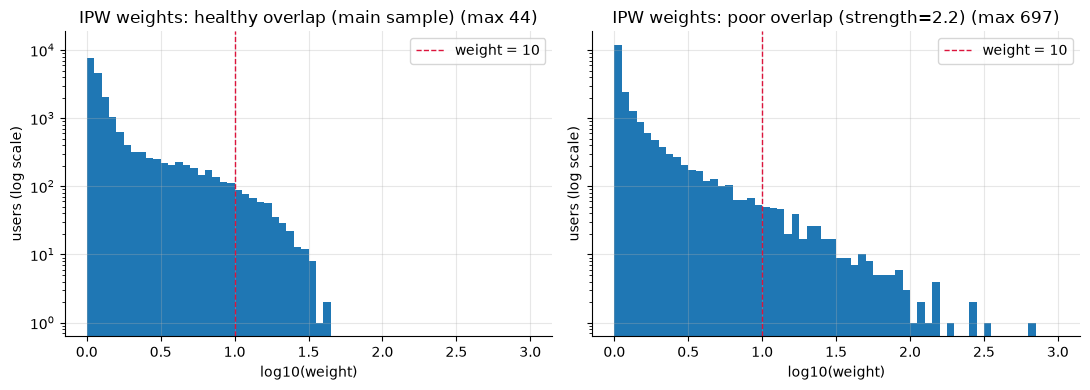

poor overlap: max weight 697, share of true PS < 0.02: 15.4%, > 0.98: 10.1%


In [10]:
rng_po = np.random.default_rng(777)
df_po = make_campaign(20_000, rng_po, strength=2.2, intercept=-4.2)
e_po = fit_ps(df_po, CONFOUNDERS, clip=1e-4)
t_po = df_po["promo"].to_numpy()
w_po = np.where(t_po == 1, 1 / e_po, 1 / (1 - e_po))
w_main = np.where(T_arr == 1, 1 / e_hat, 1 / (1 - e_hat))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, w, label in [(axes[0], w_main, "healthy overlap (main sample)"),
                     (axes[1], w_po, "poor overlap (strength=2.2)")]:
    ax.hist(np.log10(w), bins=np.linspace(0, 3, 61))
    ax.set_yscale("log")     # log counts: the tail is the whole story
    ax.set(title=f"IPW weights: {label} (max {w.max():,.0f})",
           xlabel="log10(weight)", ylabel="users (log scale)")
    ax.axvline(np.log10(10), color="crimson", ls="--", lw=1, label="weight = 10")
    ax.legend()
plt.tight_layout()
plt.show()
print(f"poor overlap: max weight {w_po.max():,.0f}, "
      f"share of true PS < 0.02: {(df_po['e_true'] < 0.02).mean():.1%}, > 0.98: {(df_po['e_true'] > 0.98).mean():.1%}")

In [11]:
M, n_mc = 200, 4000
rng_mc1 = np.random.default_rng(77)
po_res = {"truth": [], "ht": [], "hajek": [], "hajek_clip02": []}
for _ in range(M):
    d = make_campaign(n_mc, rng_mc1, strength=2.2, intercept=-4.2)
    y, t = d["spend_next"].to_numpy(), d["promo"].to_numpy()
    e = fit_ps(d, CONFOUNDERS, clip=1e-4)
    po_res["truth"].append(d["tau"].mean())
    po_res["ht"].append(ipw_ht(y, t, e))
    po_res["hajek"].append(ipw_hajek(y, t, e))
    po_res["hajek_clip02"].append(ipw_hajek(y, t, np.clip(e, 0.02, 0.98)))

truth_po = np.array(po_res.pop("truth"))
print(f"Poor-overlap Monte Carlo ({M} reps, n={n_mc}), errors vs each replicate's true ATE:")
print(f"{'estimator':<22}{'bias':>8}{'SD':>8}{'RMSE':>8}")
for k, v in po_res.items():
    err = np.array(v) - truth_po
    print(f"{k:<22}{err.mean():>8.2f}{err.std():>8.2f}{np.sqrt((err**2).mean()):>8.2f}")

Poor-overlap Monte Carlo (200 reps, n=4000), errors vs each replicate's true ATE:
estimator                 bias      SD    RMSE
ht                        0.74   23.12   23.13
hajek                     1.99    5.52    5.87
hajek_clip02              6.48    1.74    6.71


Three lessons interviewers love:

1. **Horvitz–Thompson is dominated by Hajek**: HT is (nearly) unbiased even here, but its
   SD is ~4x Hajek's — a handful of huge weights toss the raw-sum estimate around, and
   normalizing the weights wins decisively on RMSE. Always normalize (equivalently, use
   stabilized weights).
2. **Clipping the PS trades variance for bias**: clipping at 0.02 crushes the SD (to ~1.7)
   but *adds ~6.5 of systematic bias*, because here a large chunk of the population
   genuinely has near-zero treatment probability — clipping silently pretends otherwise.
   It is a dial, not a free lunch (exercise 2 maps the dial); with overlap this poor, the
   honest answers are to change the estimand (trim and report the overlap population) or
   change the design.
3. Even Hajek carries a couple dollars of bias here (it is a ratio estimator, and the
   near-violated positivity makes the tails brutal): when true propensities pile up near
   0, **no reweighting scheme is comfortable** — the data simply lack counterfactuals.

### 3d. Outcome regression adjustment (g-computation)

Model the outcome instead of the treatment: fit $\hat\mu_1(x) = E[Y \mid T{=}1, X{=}x]$ and
$\hat\mu_0(x)$ separately (a "T-learner" — it allows effect heterogeneity, unlike a single
additive-treatment regression), then average $\hat\mu_1(X_i) - \hat\mu_0(X_i)$ over
everyone. This is the same regression-adjustment idea as
[../01_statistical_foundations/03_regression_the_workhorse.ipynb](../01_statistical_foundations/03_regression_the_workhorse.ipynb),
pointed at a counterfactual mean.

In [12]:
def ols_fit(X, y):
    Xd = np.column_stack([np.ones(len(X)), X])
    beta, *_ = np.linalg.lstsq(Xd, y, rcond=None)
    return beta


def ols_pred(beta, X):
    return np.column_stack([np.ones(len(X)), X]) @ beta


Xc = dfa[CONFOUNDERS].to_numpy()
mu1_hat = ols_pred(ols_fit(Xc[is_t], Y_arr[is_t]), Xc)
mu0_hat = ols_pred(ols_fit(Xc[~is_t], Y_arr[~is_t]), Xc)
or_ate = np.mean(mu1_hat - mu0_hat)
print(f"outcome-regression ATE = {or_ate:.2f}   (true {true_ate_t:.2f})")

outcome-regression ATE = 11.46   (true 11.95)


### Scoreboard so far (single sample, correct specifications)

In [13]:
naive_t = Y_arr[is_t].mean() - Y_arr[~is_t].mean()
scoreboard = pd.DataFrame([
    ("naive difference in means", "ATE", naive_t, true_ate_t),
    ("PS stratification (10 strata)", "ATE", strat_ate10, true_ate_t),
    ("PS stratification (10, treated-wt)", "ATT", strat_att10, true_att_t),
    ("1-NN matching on PS", "ATT", att_match, true_att_t),
    ("IPW Horvitz-Thompson", "ATE", ipw_ht(Y_arr, T_arr, e_hat), true_ate_t),
    ("IPW Hajek (stabilized)", "ATE", ipw_hajek(Y_arr, T_arr, e_hat), true_ate_t),
    ("outcome regression (T-learner)", "ATE", or_ate, true_ate_t),
], columns=["estimator", "estimand", "estimate", "truth"])
scoreboard["error"] = scoreboard["estimate"] - scoreboard["truth"]
scoreboard.round(2)

,estimator,estimand,estimate,truth,error
0,naive difference in means,ATE,40.050,11.950,28.100
1,PS stratification (10 strata),ATE,12.630,11.950,0.680
2,"PS stratification (10, treated-wt)",ATT,17.540,14.920,2.610
3,1-NN matching on PS,ATT,14.540,14.920,-0.390
4,IPW Horvitz-Thompson,ATE,12.050,11.950,0.100
5,IPW Hajek (stabilized),ATE,11.720,11.950,-0.220
6,outcome regression (T-learner),ATE,11.460,11.950,-0.490


With correct specifications and healthy overlap, everything except the naive comparison
lands close to its truth. The interesting question — the one interviews probe — is what
happens when your models are *wrong*. Enter doubly robust estimation.

## 4. Doubly robust estimation: AIPW

Augmented IPW combines both nuisance models:

$$\hat\tau_{AIPW} = \frac{1}{n}\sum_i \left[\hat\mu_1(X_i) - \hat\mu_0(X_i)
+ \frac{T_i\,(Y_i - \hat\mu_1(X_i))}{\hat e(X_i)}
- \frac{(1-T_i)\,(Y_i - \hat\mu_0(X_i))}{1 - \hat e(X_i)}\right]$$

Read it as **outcome regression + IPW-weighted residual correction**. Why it's worth
knowing cold:

- **Double robustness**: consistent if *either* $\hat e$ *or* $(\hat\mu_1, \hat\mu_0)$ is
  correctly specified. If $\hat\mu$ is right, the residual corrections vanish in
  expectation regardless of $\hat e$; if $\hat e$ is right, the weighted residuals exactly
  cancel the bias of a wrong $\hat\mu$.
- **Efficiency**: with both models correct it attains the semiparametric efficiency bound —
  asymptotically you cannot do better without more assumptions.
- **Honest SEs for free**: the summand $\psi_i$ is the (efficient) influence function, so
  $\widehat{SE} = \mathrm{sd}(\psi_i)/\sqrt{n}$ — no bootstrap needed.
- **ML-friendly**: the bias of AIPW scales like the *product* of the two nuisance errors
  (rate double robustness), which is why it is the backbone of double/debiased ML — with
  the crucial caveat that flexible nuisances must be **cross-fitted** (see exercise 3).

In [14]:
def aipw_ate(y, t, e, mu1, mu0):
    """AIPW point estimate and influence-function-based SE."""
    psi = mu1 - mu0 + t * (y - mu1) / e - (1 - t) * (y - mu0) / (1 - e)
    return psi.mean(), psi.std(ddof=1) / np.sqrt(len(psi))


aipw_est, aipw_se = aipw_ate(Y_arr, T_arr, e_hat, mu1_hat, mu0_hat)
print(f"AIPW ATE = {aipw_est:.2f}  (SE {aipw_se:.2f}, 95% CI "
      f"[{aipw_est - 1.96 * aipw_se:.2f}, {aipw_est + 1.96 * aipw_se:.2f}])")
print(f"true ATE on analysis sample = {true_ate_t:.2f} -> inside the CI")

AIPW ATE = 11.46  (SE 0.47, 95% CI [10.54, 12.39])
true ATE on analysis sample = 11.95 -> inside the CI


### The money experiment: break the models on purpose

Doubly robust claims deserve a stress test. We define one deliberately *wrong* version of
each nuisance model — both are mistakes a competent-but-rushed analyst actually makes:

- **Wrong PS model**: logistic on `sessions_wk` and `tenure_m` only — `past_spend` never
  made it into the feature join, so a key confounder is missing.
- **Wrong outcome model**: one pooled OLS `spend_next ~ promo + sessions_wk + tenure_m +
  past_spend` — *raw* dollars instead of log (wrong functional form for a long-tailed
  variable) plus a constant-effect assumption.

Then we Monte Carlo 200 fresh campaigns and score IPW, outcome regression, and all four
AIPW combinations against each replicate's true ATE.

In [15]:
WRONG_PS_COLS = ["sessions_wk", "tenure_m"]
WRONG_OR_COLS = ["sessions_wk", "tenure_m", "past_spend"]

M, n_mc = 200, 4000
rng_mc2 = np.random.default_rng(2024)
cols = ["naive", "ipw_ps_ok", "ipw_ps_bad", "or_ok", "or_bad",
        "aipw_ok_ok", "aipw_ok_badOR", "aipw_badPS_ok", "aipw_bad_bad"]
mc = {c: [] for c in ["truth"] + cols}

for _ in range(M):
    d = make_campaign(n_mc, rng_mc2)
    y, t = d["spend_next"].to_numpy(), d["promo"].to_numpy()
    e_ok = fit_ps(d, CONFOUNDERS)
    e_bad = fit_ps(d, WRONG_PS_COLS)

    X_ok = d[CONFOUNDERS].to_numpy()
    m1_ok = ols_pred(ols_fit(X_ok[t == 1], y[t == 1]), X_ok)
    m0_ok = ols_pred(ols_fit(X_ok[t == 0], y[t == 0]), X_ok)

    X_bad = d[WRONG_OR_COLS].to_numpy()
    beta_bad = ols_fit(np.column_stack([t, X_bad]), y)
    m1_bad = ols_pred(beta_bad, np.column_stack([np.ones(n_mc), X_bad]))
    m0_bad = ols_pred(beta_bad, np.column_stack([np.zeros(n_mc), X_bad]))

    mc["truth"].append(d["tau"].mean())
    mc["naive"].append(y[t == 1].mean() - y[t == 0].mean())
    mc["ipw_ps_ok"].append(ipw_hajek(y, t, e_ok))
    mc["ipw_ps_bad"].append(ipw_hajek(y, t, e_bad))
    mc["or_ok"].append(np.mean(m1_ok - m0_ok))
    mc["or_bad"].append(np.mean(m1_bad - m0_bad))
    mc["aipw_ok_ok"].append(aipw_ate(y, t, e_ok, m1_ok, m0_ok)[0])
    mc["aipw_ok_badOR"].append(aipw_ate(y, t, e_ok, m1_bad, m0_bad)[0])
    mc["aipw_badPS_ok"].append(aipw_ate(y, t, e_bad, m1_ok, m0_ok)[0])
    mc["aipw_bad_bad"].append(aipw_ate(y, t, e_bad, m1_bad, m0_bad)[0])

truth_mc = np.array(mc.pop("truth"))
labels = {
    "naive": ("naive diff-in-means", "-", "-"),
    "ipw_ps_ok": ("IPW", "correct", "-"),
    "ipw_ps_bad": ("IPW", "WRONG", "-"),
    "or_ok": ("outcome regression", "-", "correct"),
    "or_bad": ("outcome regression", "-", "WRONG"),
    "aipw_ok_ok": ("AIPW", "correct", "correct"),
    "aipw_ok_badOR": ("AIPW", "correct", "WRONG"),
    "aipw_badPS_ok": ("AIPW", "WRONG", "correct"),
    "aipw_bad_bad": ("AIPW", "WRONG", "WRONG"),
}
recs = []
for c in cols:
    err = np.array(mc[c]) - truth_mc
    name, ps_spec, or_spec = labels[c]
    recs.append((name, ps_spec, or_spec, err.mean(), err.std(), np.sqrt((err ** 2).mean())))
money = pd.DataFrame(recs, columns=["estimator", "PS model", "outcome model", "bias", "SD", "RMSE"])
money.round(2)

,estimator,PS model,outcome model,bias,SD,RMSE
0,naive diff-in-means,-,-,29.360,1.090,29.380
1,IPW,correct,-,0.240,1.350,1.370
2,IPW,WRONG,-,3.100,1.310,3.360
3,outcome regression,-,correct,-0.040,0.900,0.900
4,outcome regression,-,WRONG,5.040,0.980,5.130
5,AIPW,correct,correct,0.030,1.070,1.070
6,AIPW,correct,WRONG,-0.040,1.160,1.160
7,AIPW,WRONG,correct,0.020,1.060,1.060
8,AIPW,WRONG,WRONG,3.130,1.190,3.350


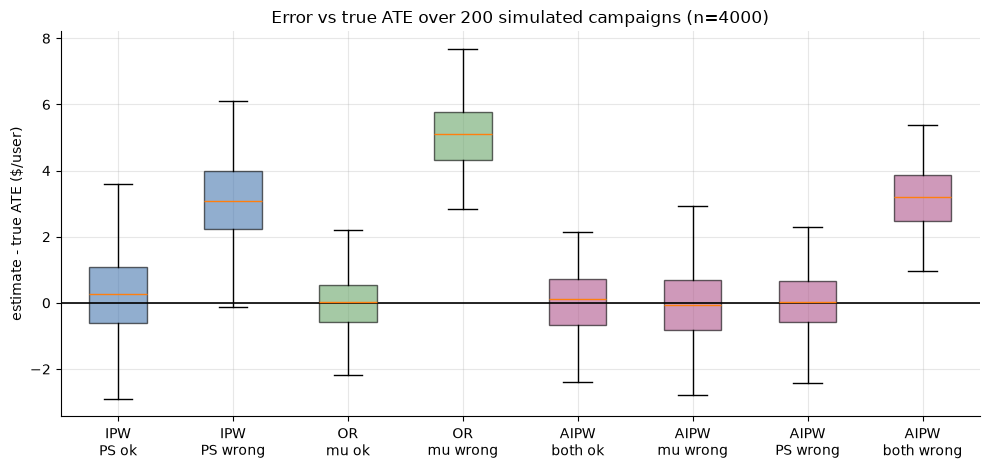

In [16]:
plot_cols = cols[1:]  # drop naive: its bias would dwarf the plot
fig, ax = plt.subplots(figsize=(10, 4.8))
data_bp = [np.array(mc[c]) - truth_mc for c in plot_cols]
colors = ["#4878b0", "#4878b0", "#6aa66a", "#6aa66a", "#b0568c", "#b0568c", "#b0568c", "#b0568c"]
bp = ax.boxplot(data_bp, patch_artist=True, showfliers=False)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax.axhline(0, color="black", lw=1.2)
ax.set_xticklabels(["IPW\nPS ok", "IPW\nPS wrong", "OR\nmu ok", "OR\nmu wrong",
                    "AIPW\nboth ok", "AIPW\nmu wrong", "AIPW\nPS wrong", "AIPW\nboth wrong"])
ax.set(title=f"Error vs true ATE over {M} simulated campaigns (n={n_mc})",
       ylabel="estimate - true ATE ($/user)")
plt.tight_layout()
plt.show()

The doubly robust promise, verified:

- **Single-model estimators fail with a wrong model**: IPW with the confounder-less PS and
  the pooled raw-dollar regression are both biased by several dollars — a quarter to
  nearly half of the true effect — and the bias does not shrink with more data.
- **AIPW survives either single failure**: with a wrong outcome model *or* a wrong PS
  model, its bias stays ~0 — the correct half of the estimator repairs the wrong half.
- **Both wrong = no rescue**: AIPW inherits essentially the wrong-PS bias. DR is
  "two chances to be right", not "no chances needed". (In pathological cases — Kang &
  Schafer 2007 — both-wrong AIPW can even be *worse* than either single estimator.)
- The SD column shows the price of robustness is small: AIPW (~1.1) sits between the
  correctly-specified outcome regression (~0.9, the efficiency king *when its parametric
  model is exactly right* — a bet you can never verify) and IPW (~1.4). Trading a few
  percent of precision for insurance against misspecification is an easy buy.

## 5. Balance diagnostics: the love plot

The deliverable for any weighting analysis is a **before/after balance table**: SMDs on the
raw sample vs SMDs computed with stabilized IPW weights. Convention: post-weighting
|SMD| < 0.1 for every confounder. We compute it for the correct PS *and* for the wrong PS
from the money experiment — because this diagnostic is exactly how you would *catch* that
wrong model in real life, where no oracle tells you.

             unweighted  weighted (correct PS)  weighted (wrong PS)
sessions_wk       1.266                  0.007               -0.050
tenure_m          0.084                 -0.006                0.006
past_spend        0.876                  0.031                0.209
log_spend         1.191                  0.017                0.272
power_user        1.124                  0.005                0.041


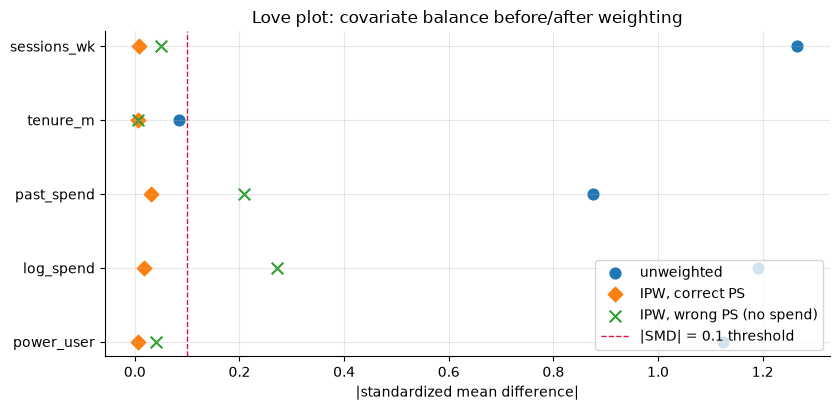

In [17]:
p_treat = T_arr.mean()
w_stab_ok = np.where(T_arr == 1, p_treat / e_hat, (1 - p_treat) / (1 - e_hat))
e_bad_main = fit_ps(dfa, WRONG_PS_COLS)
w_stab_bad = np.where(T_arr == 1, p_treat / e_bad_main, (1 - p_treat) / (1 - e_bad_main))

bal = pd.DataFrame({
    "unweighted": [smd(dfa[c].to_numpy(), T_arr) for c in OBSERVED],
    "weighted (correct PS)": [smd(dfa[c].to_numpy(), T_arr, w_stab_ok) for c in OBSERVED],
    "weighted (wrong PS)": [smd(dfa[c].to_numpy(), T_arr, w_stab_bad) for c in OBSERVED],
}, index=OBSERVED)
print(bal.round(3).to_string())

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ypos = np.arange(len(OBSERVED))
ax.scatter(bal["unweighted"].abs(), ypos, label="unweighted", marker="o", s=60)
ax.scatter(bal["weighted (correct PS)"].abs(), ypos, label="IPW, correct PS", marker="D", s=55)
ax.scatter(bal["weighted (wrong PS)"].abs(), ypos, label="IPW, wrong PS (no spend)", marker="x", s=70)
ax.axvline(0.1, color="crimson", ls="--", lw=1, label="|SMD| = 0.1 threshold")
ax.set_yticks(ypos, OBSERVED)
ax.set(title="Love plot: covariate balance before/after weighting",
       xlabel="|standardized mean difference|")
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

The correct PS pulls every confounder comfortably under 0.1. The wrong PS balances what it
modeled (sessions, tenure) but leaves `log_spend` / `past_spend` far out of tolerance —
a flashing red light that would have warned us of the ~3-dollar IPW bias *without knowing
the truth*. Balance checking is not bureaucracy; it is the test suite for your PS model.

## 6. Pitfalls

### Pitfall 1: conditioning on post-treatment variables

"Control for everything" instincts destroy causal estimates. Suppose the promo works
partly by bringing users back to the app (promo -> sessions after -> spend). An analyst
who "controls for engagement" using *post-campaign* sessions blocks the causal path they
are trying to measure. To isolate the damage, simulate a **randomized** promo (so nothing
is confounded) and watch adjustment for a mediator wreck it anyway.

In [18]:
rng_med = np.random.default_rng(7)
n_med = 20_000
sess_before = rng_med.gamma(2.0, 1.6, n_med)
promo_r = rng_med.binomial(1, 0.5, n_med)                      # randomized!
sess_after = sess_before + 1.2 * promo_r + rng_med.normal(0, 0.8, n_med)   # mediator
spend_med = 30 + 8.0 * sess_after + 2.0 * sess_before + rng_med.normal(0, 15, n_med)
true_total = 8.0 * 1.2

b_ok = ols_fit(np.column_stack([promo_r, sess_before]), spend_med)
b_bad = ols_fit(np.column_stack([promo_r, sess_before, sess_after]), spend_med)
print(f"true total effect of promo             : {true_total:.2f}")
print(f"adjusting for PRE-treatment sessions   : {b_ok[1]:+.2f}   (correct)")
print(f"also adjusting for POST-treat sessions : {b_bad[1]:+.2f}   (effect erased!)")

true total effect of promo             : 9.60
adjusting for PRE-treatment sessions   : +9.31   (correct)
also adjusting for POST-treat sessions : -0.64   (effect erased!)


The rule: the adjustment set (for the PS *and* the outcome model) may contain only
**pre-treatment** variables. Conditioning on mediators eats the effect; conditioning on
post-treatment colliders (e.g. analyzing only users who *redeemed* the promo) manufactures
bias out of thin air. The full taxonomy of good vs bad controls is in
[01_potential_outcomes_dags.ipynb](01_potential_outcomes_dags.ipynb).

### Pitfall 2: unobserved confounding — no estimator saves you

Everything above assumed unconfoundedness given $X$. If a confounder is *unobserved*,
propensity scores, matching, and AIPW are all biased — DR means robust to
*misspecification*, not to *missing variables*. What a senior candidate offers instead is
**sensitivity analysis**: how strong would a hidden confounder have to be to change the
conclusion? We rerun the DGP with a latent trait `u` that raises both promo probability
(coefficient $\gamma$ on the logit) and baseline spend ($4\gamma$ dollars per SD), then
watch the fully-correct AIPW drift.

 gamma  AIPW estimate  true ATE  bias  inflation
 0.000         12.170    12.010 0.160      0.010
 0.300         12.540    12.000 0.540      0.050
 0.600         13.460    12.010 1.450      0.120
 0.900         14.800    12.010 2.780      0.230
 1.200         16.880    11.990 4.890      0.410
 1.500         18.690    11.990 6.700      0.560


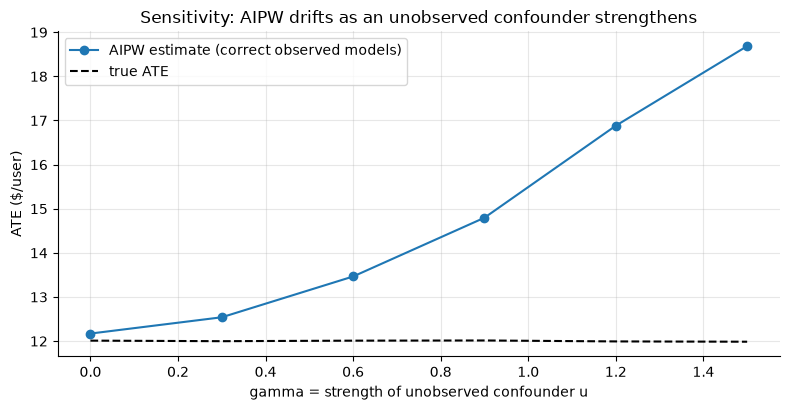

In [19]:
gammas = [0.0, 0.3, 0.6, 0.9, 1.2, 1.5]
rng_sens = np.random.default_rng(314)
R_sens, n_sens = 8, 10_000        # average a few replicates per gamma to smooth MC noise
sens_est, sens_truth = [], []
for g in gammas:
    ests, truths = [], []
    for _ in range(R_sens):
        d = make_campaign(n_sens, rng_sens, gamma_u=g)
        y, t = d["spend_next"].to_numpy(), d["promo"].to_numpy()
        e = fit_ps(d, CONFOUNDERS)                  # u is NOT observable -> not in the model
        X = d[CONFOUNDERS].to_numpy()
        m1 = ols_pred(ols_fit(X[t == 1], y[t == 1]), X)
        m0 = ols_pred(ols_fit(X[t == 0], y[t == 0]), X)
        ests.append(aipw_ate(y, t, e, m1, m0)[0])
        truths.append(d["tau"].mean())
    sens_est.append(np.mean(ests))
    sens_truth.append(np.mean(truths))

sens = pd.DataFrame({"gamma": gammas, "AIPW estimate": sens_est, "true ATE": sens_truth})
sens["bias"] = sens["AIPW estimate"] - sens["true ATE"]
sens["inflation"] = sens["bias"] / sens["true ATE"]
print(sens.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(gammas, sens_est, marker="o", label="AIPW estimate (correct observed models)")
ax.plot(gammas, sens_truth, ls="--", color="black", label="true ATE")
ax.set(title="Sensitivity: AIPW drifts as an unobserved confounder strengthens",
       xlabel="gamma = strength of unobserved confounder u", ylabel="ATE ($/user)")
ax.legend()
plt.tight_layout()
plt.show()

For scale: in this DGP one SD of *log past spend* moves the treatment logit by ~0.65 — so
$\gamma = 0.6$ means "a hidden trait about as predictive of treatment as past spend, with a
far weaker outcome effect", and it already inflates the estimate by ~12% (about 23% by
$\gamma = 0.9$, over 50% at $\gamma = 1.5$). The
interview-ready phrasing: *"my estimate is robust unless there is an unmeasured confounder
comparable in strength to my strongest observed one"* — and formal tools (Rosenbaum bounds,
the E-value, Cinelli–Hazlett robustness values) make exactly this statement precise.
When plausible confounders lurk, reach for design-based methods instead:
[03_did_synthetic_control.ipynb](03_did_synthetic_control.ipynb) and
[04_iv_rdd.ipynb](04_iv_rdd.ipynb).

### Pitfall 3: judging the PS model by AUC

The PS model is **not a prediction task**. Its job is to produce weights that balance
covariates — not to classify who got the promo. Chasing AUC actively hurts, in two ways:

1. An *overfit* model separates the classes in-sample ($\hat e_i \to T_i$), which drives
   all weights toward 1 — IPW then collapses back to the naive comparison.
2. Even an *honest* high AUC is bad news: it means assignment is nearly deterministic in
   $X$, i.e. overlap is dying and no weighting method has data to work with.

In [20]:
overfit = lgb.LGBMClassifier(n_estimators=400, num_leaves=63, min_child_samples=2,
                             learning_rate=0.1, random_state=42, n_jobs=1, verbose=-1)
overfit.fit(dfa[CONFOUNDERS], T_arr)
e_over = np.clip(overfit.predict_proba(dfa[CONFOUNDERS])[:, 1], 0.001, 0.999)

w_stab_over = np.where(T_arr == 1, p_treat / e_over, (1 - p_treat) / (1 - e_over))
print(f"{'PS model':<28}{'AUC':>7}{'IPW ATE':>10}{'SMD log_spend (wtd)':>22}")
print(f"{'logistic, correct spec':<28}{roc_auc_score(T_arr, e_hat):>7.3f}"
      f"{ipw_hajek(Y_arr, T_arr, e_hat):>10.2f}{smd(dfa['log_spend'].to_numpy(), T_arr, w_stab_ok):>22.3f}")
print(f"{'LGBM overfit (in-sample)':<28}{roc_auc_score(T_arr, e_over):>7.3f}"
      f"{ipw_hajek(Y_arr, T_arr, e_over):>10.2f}{smd(dfa['log_spend'].to_numpy(), T_arr, w_stab_over):>22.3f}")
print(f"\nnaive difference on this sample: {naive_t:.2f}   true ATE: {true_ate_t:.2f}")
print("higher AUC, worse everything: the overfit PS pushes IPW back toward the naive answer")
print("and leaves log_spend badly imbalanced. Balance is the success criterion, not AUC.")

PS model                        AUC   IPW ATE   SMD log_spend (wtd)
logistic, correct spec        0.828     11.72                 0.017
LGBM overfit (in-sample)      0.993     31.65                 0.868

naive difference on this sample: 40.05   true ATE: 11.95
higher AUC, worse everything: the overfit PS pushes IPW back toward the naive answer
and leaves log_spend badly imbalanced. Balance is the success criterion, not AUC.


The overfit model *wins on AUC by a mile* and produces a nearly-naive, badly-imbalanced
estimate. If you want flexible ML propensities, they must be regularized and
**cross-fitted** (out-of-fold predictions — same discipline as
[../04_ml_tabular/02_leakage_validation.ipynb](../04_ml_tabular/02_leakage_validation.ipynb)),
and even then you check balance, not AUC. Exercise 3 builds that correctly.

## Interview corner

**Q1. "We sent the promo to users chosen by a targeting model — no holdout. Estimate its
effect."**
Strong answer: state the identification assumptions out loud (unconfoundedness given the
targeting features, positivity); demand the targeting inputs as the adjustment set (if
assignment was `f(X)` and you observe `X`, unconfoundedness holds by construction — but if
targeting was deterministic, positivity fails and no method works); check overlap, trim;
estimate with AIPW; validate with balance diagnostics; report a sensitivity analysis. Bonus:
propose shipping future campaigns with a small randomized holdout.

**Q2. "What does doubly robust buy you?"**
Consistency if either the PS model or the outcome model is correct; semiparametric
efficiency when both are; bias that scales as the *product* of nuisance errors, enabling
ML nuisances with cross-fitting (DML). It does not fix unobserved confounding or a lack of
overlap, and with both models badly wrong it can fail too.

**Q3. "How do you validate a propensity model?"**
Balance: post-weighting |SMD| < 0.1 on every confounder (love plot). Overlap: PS
distributions by arm, trimmed share, effective sample size, max weights. Calibration of
predicted probabilities matters (weights are inverse *probabilities*); discrimination (AUC)
does not — high AUC is a symptom of positivity problems, not success.

**Q4. "Your IPW confidence interval is enormous. What do you do?"**
Diagnose the weights (max, ESS). Use Hajek/stabilized weights, not Horvitz–Thompson.
Trim/clip and *say the estimand changed*. Move to AIPW (residual weighting is gentler) or
matching/overlap weights. If overlap is fundamentally absent, the honest answer is that
this population's question needs a different design.

**Q5. "Matching vs weighting vs regression — how do you choose?"**
Estimand first: 1-NN matching naturally targets ATT; IPW/AIPW flexibly target ATE or ATT.
Matching is transparent and robust to outcome-model form but inefficient and awkward for
SEs; weighting uses everyone but is fragile to extreme weights; regression is efficient but
fully model-dependent and extrapolates silently where overlap is thin. In practice: AIPW,
with matching as a legibility/robustness check.

**Q6. "The PS model has AUC 0.97. Good news?"**
No — near-deterministic assignment means near-zero overlap: the groups barely share
support, weights explode, and estimates hinge on extrapolation. Either find the region of
common support and re-scope the question, or find a different identification strategy.

**Q7. "How do you address unobserved confounding?"**
You cannot test it, so you (a) argue substantively from the assignment mechanism,
(b) quantify sensitivity (E-values, Rosenbaum bounds, benchmarking against strongest
observed confounders), (c) use negative-control outcomes/exposures as falsification, and
(d) prefer designs that don't need unconfoundedness — DiD, synthetic control, IV, RDD
(see [03_did_synthetic_control.ipynb](03_did_synthetic_control.ipynb),
[04_iv_rdd.ipynb](04_iv_rdd.ipynb)).

## Key takeaways

- Naive treated-vs-untreated comparisons on targeted campaigns can overstate effects
  several-fold; here 3.5x. Always ask "who got the treatment and why?"
- The propensity score is a *balancing score*: conditioning on the scalar $e(X)$ balances
  the whole covariate vector — verified directly within PS strata.
- Check overlap before estimating anything; trim to common support and be explicit that
  the estimand becomes the overlap population.
- Keep estimands straight: matching-on-treated estimates the ATT; with heterogeneous
  effects ATT ≠ ATE (here $14.9 vs $12.0).
- Never use raw Horvitz–Thompson weighting; normalize (Hajek/stabilized weights). Clipping
  weights trades bias for variance — a dial to report, not a fix to hide.
- AIPW = outcome model + IPW correction: consistent if either nuisance model is right,
  efficient if both are, SEs free from the influence function. It is the default answer.
- Doubly robust ≠ bulletproof: both models wrong, unobserved confounding, or no overlap
  still sink you.
- Validate the PS with balance (|SMD| < 0.1) and overlap diagnostics — never AUC. An
  overfit PS silently turns IPW back into the naive comparison.
- Only pre-treatment variables belong in the adjustment set; conditioning on mediators or
  post-treatment colliders destroys even randomized comparisons.
- Always ship a sensitivity analysis: "how strong must a hidden confounder be to change
  the decision?"

## Exercises

**Exercise 1 — ATT by weighting.** IPW can target the ATT with *odds weights*: treated
users get weight 1, controls get $\hat e/(1-\hat e)$ (reweighting controls to the treated
covariate distribution). Implement it on the analysis sample and compare with the matching
ATT and the true ATT.

**Exercise 2 — the clipping dial.** On the poor-overlap DGP (`strength=2.2,
intercept=-4.2`), Monte Carlo the Hajek estimator with PS clipped at
$\varepsilon \in \{10^{-4}, 0.005, 0.01, 0.02, 0.05, 0.1\}$. Plot bias, SD, and RMSE vs
$\varepsilon$. Where is the RMSE optimum, and what does that tell you about default
clipping rules?

**Exercise 3 — ML nuisances done right.** Replace both nuisance models with regularized,
**cross-fitted** LightGBM models (out-of-fold predictions, `n_jobs=1`). Compare (a) IPW
using the ML propensity alone vs (b) AIPW using both ML nuisances, against the true ATE.
What does this say about plugging ML into causal pipelines?

In [21]:
# --- Solution 1: ATT via odds weighting ---
w_odds = np.where(T_arr == 1, 1.0, e_hat / (1 - e_hat))
att_odds = (Y_arr[is_t].mean()
            - np.average(Y_arr[~is_t], weights=w_odds[~is_t]))
print(f"ATT via odds weighting : {att_odds:.2f}")
print(f"ATT via 1-NN matching  : {att_match:.2f}")
print(f"true ATT               : {true_att_t:.2f}")
print("Weighting uses every control (efficient); matching used only "
      f"{len(np.unique(idx)):,} distinct controls. Both target the same estimand.")

ATT via odds weighting : 15.60
ATT via 1-NN matching  : 14.54
true ATT               : 14.92
Weighting uses every control (efficient); matching used only 2,665 distinct controls. Both target the same estimand.


  clip   bias    SD   RMSE
0.0001  2.460 3.640  4.390
 0.005  3.240 2.800  4.280
  0.01  4.420 2.260  4.960
  0.02  6.530 1.830  6.790
  0.05 10.900 1.370 10.980
   0.1 15.580 1.170 15.620


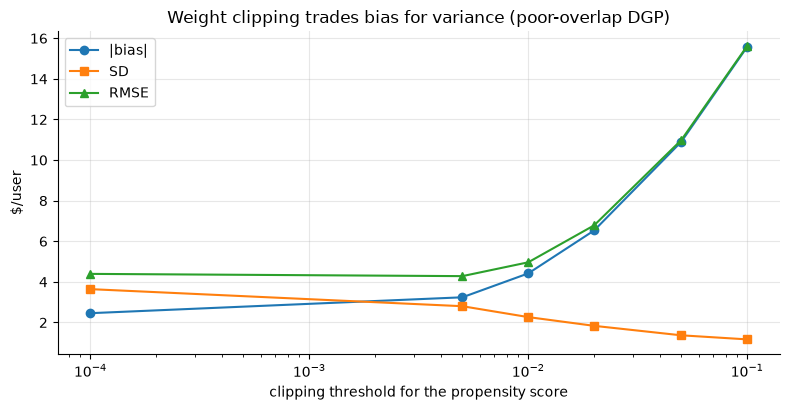

Mild clipping (~0.005) buys a real variance reduction for little extra bias and slightly improves RMSE; past that, bias grows much faster than variance shrinks and RMSE deteriorates. The optimum is problem-specific - there is no universally safe default, so report the dial (estimates across thresholds), or fix the design.


In [22]:
# --- Solution 2: the clipping dial ---
clip_grid = [1e-4, 0.005, 0.01, 0.02, 0.05, 0.10]
M2, n2 = 150, 4000
rng_clip = np.random.default_rng(123)
ests = {c: [] for c in clip_grid}
truths2 = []
for _ in range(M2):
    d = make_campaign(n2, rng_clip, strength=2.2, intercept=-4.2)
    y, t = d["spend_next"].to_numpy(), d["promo"].to_numpy()
    e_raw = fit_ps(d, CONFOUNDERS, clip=1e-6)
    truths2.append(d["tau"].mean())
    for c in clip_grid:
        ests[c].append(ipw_hajek(y, t, np.clip(e_raw, c, 1 - c)))
truths2 = np.array(truths2)

clip_tab = pd.DataFrame({
    "clip": [f"{c:g}" for c in clip_grid],
    "bias": [np.mean(np.array(ests[c]) - truths2) for c in clip_grid],
    "SD": [np.std(np.array(ests[c]) - truths2) for c in clip_grid],
})
clip_tab["RMSE"] = np.sqrt(clip_tab["bias"] ** 2 + clip_tab["SD"] ** 2)
print(clip_tab.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(clip_grid, clip_tab["bias"].abs(), marker="o", label="|bias|")
ax.plot(clip_grid, clip_tab["SD"], marker="s", label="SD")
ax.plot(clip_grid, clip_tab["RMSE"], marker="^", label="RMSE")
ax.set_xscale("log")
ax.set(title="Weight clipping trades bias for variance (poor-overlap DGP)",
       xlabel="clipping threshold for the propensity score", ylabel="$/user")
ax.legend()
plt.tight_layout()
plt.show()
print("Mild clipping (~0.005) buys a real variance reduction for little extra bias and "
      "slightly improves RMSE; past that, bias grows much faster than variance shrinks and "
      "RMSE deteriorates. The optimum is problem-specific - there is no universally safe "
      "default, so report the dial (estimates across thresholds), or fix the design.")

In [23]:
# --- Solution 3: cross-fitted ML nuisances (the DML recipe) ---
ps_ml = lgb.LGBMClassifier(n_estimators=150, num_leaves=15, min_child_samples=200,
                           learning_rate=0.1, random_state=42, n_jobs=1, verbose=-1)
e_cf = np.clip(cross_val_predict(ps_ml, dfa[CONFOUNDERS], T_arr, cv=5,
                                 method="predict_proba")[:, 1], 0.01, 0.99)

mu1_cf, mu0_cf = np.zeros(len(dfa)), np.zeros(len(dfa))
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for train_idx, test_idx in kf.split(dfa):
    reg1 = lgb.LGBMRegressor(n_estimators=200, num_leaves=15, min_child_samples=100,
                             learning_rate=0.1, random_state=42, n_jobs=1, verbose=-1)
    reg0 = lgb.LGBMRegressor(n_estimators=200, num_leaves=15, min_child_samples=100,
                             learning_rate=0.1, random_state=42, n_jobs=1, verbose=-1)
    tr1 = train_idx[T_arr[train_idx] == 1]
    tr0 = train_idx[T_arr[train_idx] == 0]
    reg1.fit(dfa[CONFOUNDERS].iloc[tr1], Y_arr[tr1])
    reg0.fit(dfa[CONFOUNDERS].iloc[tr0], Y_arr[tr0])
    mu1_cf[test_idx] = reg1.predict(dfa[CONFOUNDERS].iloc[test_idx])
    mu0_cf[test_idx] = reg0.predict(dfa[CONFOUNDERS].iloc[test_idx])

aipw_ml, aipw_ml_se = aipw_ate(Y_arr, T_arr, e_cf, mu1_cf, mu0_cf)
print(f"cross-fitted LGBM PS: honest AUC = {roc_auc_score(T_arr, e_cf):.3f}")
print(f"(a) IPW with ML propensity alone : {ipw_hajek(Y_arr, T_arr, e_cf):.2f}")
print(f"(b) AIPW with both ML nuisances  : {aipw_ml:.2f} (SE {aipw_ml_se:.2f})")
print(f"true ATE                         : {true_ate_t:.2f}")
print("IPW alone is fragile: tree-model probabilities are imperfectly calibrated and the "
      "weights amplify that. AIPW's outcome model absorbs the error (rate double "
      "robustness) - flexible ML belongs inside a DR estimator, cross-fitted, "
      "never as a bare weighting model.")

cross-fitted LGBM PS: honest AUC = 0.820
(a) IPW with ML propensity alone : 8.98
(b) AIPW with both ML nuisances  : 11.43 (SE 0.66)
true ATE                         : 11.95
IPW alone is fragile: tree-model probabilities are imperfectly calibrated and the weights amplify that. AIPW's outcome model absorbs the error (rate double robustness) - flexible ML belongs inside a DR estimator, cross-fitted, never as a bare weighting model.
